In [44]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
for candidate in [Path.cwd(), Path.cwd() / "ranking"]:
    if (candidate / "ranking_utils.py").exists():
        sys.path.insert(0, str(candidate))
        break
import ranking_utils as ru
import ranking_features as rf

# Quick analysis and naive models 
---

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ranking_utils as ru

teams = ru.load_teams()
teams = teams[teams["year"].between(1980, 2009)].copy()

print(teams["confID"].value_counts().to_string())
print()

years_present  = sorted(teams["year"].unique())
years_expected = list(range(1980, 2010))
missing_years  = sorted(set(years_expected) - set(years_present))

print(f"Seasons present: {years_present[0]}-{years_present[-1]} "
      f"({len(years_present)} seasons)")
print(f"Missing seasons: {missing_years} "
      f"(2004-05 lockout -> 2003 and 2005 are consecutive)")

confID
EC    373
WC    359

Seasons present: 1980-2009 (29 seasons)
Missing seasons: [2004] (2004-05 lockout -> 2003 and 2005 are consecutive)


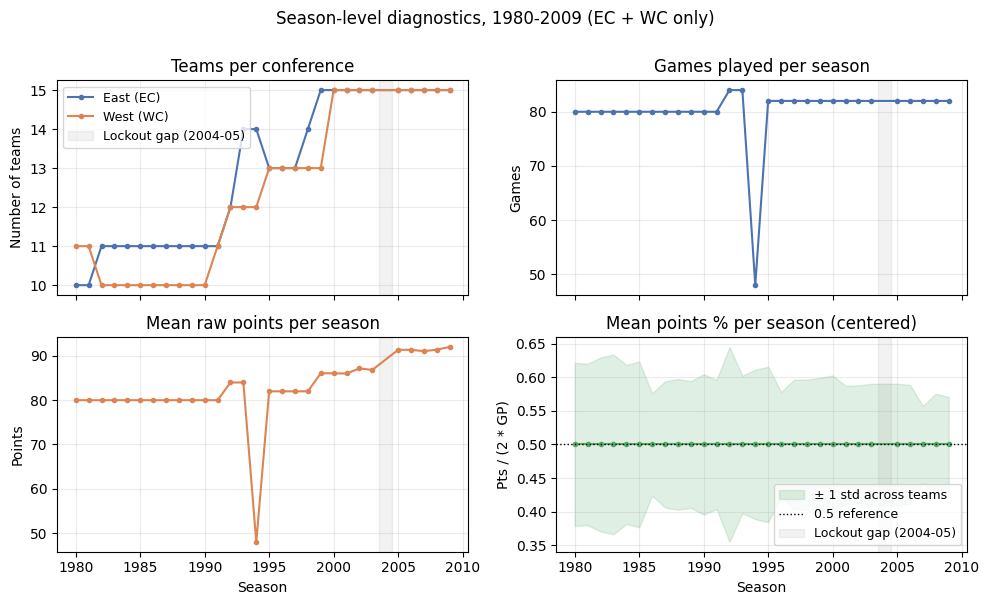


Target = z-score of pts%.  mean = -0.000, std = 0.981
Per-season mean(target): max |deviation| from 0 = 0.0000   (should be ~0)


In [46]:
season = teams.groupby("year").agg(
    games       =("games_raw",  "first"),
    points_mean =("pts_raw",    "mean"),
    pct_mean    =("pts_pct_c",  "mean"),
    pct_std     =("pts_pct_c",  "std"),
)
counts = teams.groupby(["year", "confID"]).size().unstack(fill_value=0)

short = season[season["games"] < 70]

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
lockout = dict(color="gray", alpha=0.10, label="Lockout gap (2004-05)")

# (0,0) Teams per conference ----------------------------------------------
ax = axes[0, 0]
ax.plot(counts.index, counts["EC"], marker="o", ms=3,
        label="East (EC)", color="#4C72B0")
ax.plot(counts.index, counts["WC"], marker="o", ms=3,
        label="West (WC)", color="#DD8452")
ax.axvspan(2003.5, 2004.5, **lockout)
ax.set_title("Teams per conference")
ax.set_ylabel("Number of teams")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.25)

# (0,1) Games played per season ------------------------------------------
ax = axes[0, 1]
ax.plot(season.index, season["games"], marker="o", ms=3, color="#4C72B0")
ax.axvspan(2003.5, 2004.5, **lockout)
ax.set_title("Games played per season")
ax.set_ylabel("Games")
ax.grid(alpha=0.25)

# (1,0) Mean raw points per season ---------------------------------------
ax = axes[1, 0]
ax.plot(season.index, season["points_mean"], marker="o", ms=3, color="#DD8452")
ax.axvspan(2003.5, 2004.5, **lockout)
ax.set_title("Mean raw points per season")
ax.set_xlabel("Season")
ax.set_ylabel("Points")
ax.grid(alpha=0.25)

# (1,1) Mean points % per season (centered) ------------------------------
ax = axes[1, 1]
m, s = season["pct_mean"], season["pct_std"]
ax.plot(m.index, m, marker="o", ms=3, color="#55A868")
ax.fill_between(m.index, m - s, m + s, color="#55A868", alpha=0.18,
                label="± 1 std across teams")
ax.axhline(0.5, color="black", linestyle=":", linewidth=1,
           label="0.5 reference")
ax.axvspan(2003.5, 2004.5, **lockout)
ax.set_title("Mean points % per season (centered)")
ax.set_xlabel("Season")
ax.set_ylabel("Pts / (2 * GP)")
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.25)

plt.suptitle("Season-level diagnostics, 1980-2009 (EC + WC only)",
             y=1.00, fontsize=12)
plt.tight_layout()
plt.show()

data = ru.build_dataset(teams)
print(f"\nTarget = z-score of pts%.  mean = {data['target'].mean():+.3f}, "
      f"std = {data['target'].std():.3f}")
per_year = data.groupby("year")["target"].mean()
print(f"Per-season mean(target): max |deviation| from 0 = "
      f"{per_year.abs().max():.4f}   (should be ~0)")

In [47]:
# -----------------------------------------------------------------------------
# Shared setup for the feature-selection cells below.
# The old notebook relied on `_df`, `_all_groups`, `_ext_groups` and
# `_make_model` being defined by another notebook in the same kernel.  They are
# rebuilt here so the notebook runs correctly on its own, from the project root
# or from the ranking/ directory.
# -----------------------------------------------------------------------------
_ext_df, _ext_groups = rf.build_external_features(ru.DATA_DIR)

_ext_cols = [c for cols in _ext_groups.values() for c in cols]
_missing = [c for c in _ext_cols if c not in _ext_df.columns]
if _missing:
    raise KeyError(
        f"build_external_features() did not produce: {_missing}\n"
        f"Available columns: {sorted(_ext_df.columns)}"
    )

_before = len(data)
_df = data.merge(
    _ext_df[["year", "tmID"] + _ext_cols],
    on=["year", "tmID"],
    how="left",
)
assert len(_df) == _before, "external merge changed the row count"
_df[_ext_cols] = _df[_ext_cols].fillna(0.0)

_all_groups = {**ru.feature_groups(_df), **_ext_groups}
_all_features = [c for cols in _all_groups.values() for c in cols]
_dev = _df[_df["n_hist"] >= 1]
_truth = _df[["year", "tmID", "target"]].drop_duplicates(["year", "tmID"])
_eval_years = [y for y in range(1995, 2010) if y in _df["year"].values]

from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer


def _make_model():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LinearRegression(),
    )


print(f"External feature groups: {list(_ext_groups)}")
print(f"Candidate features: {len(_all_features)} | dev rows: {len(_dev)}")


External feature groups: ['shots_luck', 'special_teams', 'goalie', 'splits', 'teamvs', 'roster', 'awards', 'playoff_history']
Candidate features: 58 | dev rows: 702


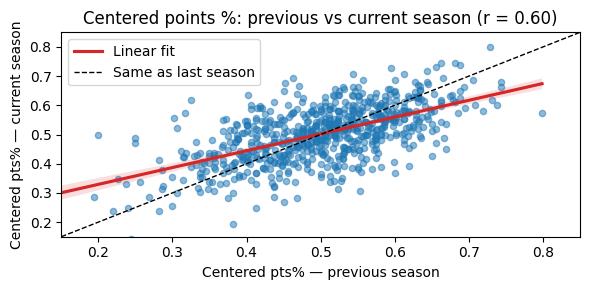

Correlation (centered pts%): 0.598
MAE (centered pts%):         0.068
  ≈ 11.2 points in an 82-game season


In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import ranking_utils as ru

pts_df = ru.load_teams()
pts_df = pts_df[pts_df["year"].between(1980, 2009)].copy()

pts_df = pts_df.sort_values(["franchID", "year"]).reset_index(drop=True)
pts_df["prev_pts_pct_c"] = (
    pts_df.groupby("franchID")["pts_pct_c"].shift(1)
)

pairs = pts_df.dropna(subset=["prev_pts_pct_c"]).copy()

correlation_coefficient = (
    pairs["prev_pts_pct_c"].corr(pairs["pts_pct_c"])
)
mean_absolute_error = (
    (pairs["prev_pts_pct_c"] - pairs["pts_pct_c"]).abs().mean()
)

fig, ax = plt.subplots(figsize=(6, 3))
sns.regplot(
    data=pairs, x="prev_pts_pct_c", y="pts_pct_c", ax=ax,
    scatter_kws={"s": 20, "alpha": 0.5},
    line_kws={"color": "#d62728", "label": "Linear fit"},
)

lims = [0.15, 0.85]
ax.plot(lims, lims, color="black", linestyle="--", linewidth=1,
        label="Same as last season")
ax.set_xlim(lims)
ax.set_ylim(lims)

ax.set_title(
    f"Centered points %: previous vs current season (r = {correlation_coefficient:.2f})"
)
ax.set_xlabel("Centered pts% — previous season")
ax.set_ylabel("Centered pts% — current season")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"Correlation (centered pts%): {correlation_coefficient:.3f}")
print(f"MAE (centered pts%):         {mean_absolute_error:.3f}")
print(f"  ≈ {mean_absolute_error * 2 * 82:.1f} points in an 82-game season")

```
This plots show that the previous season points and the current season points are strongly correlated.
This means that a naive model that predicts the same result as the past year should already be a good predictor
```

```
Given this information, we choosed to do 2 Naive Baselines :
1. Persistence   : Predicts random ranks
2. Random        : Predicts the same rank as the previous year
```

In [49]:
teams = ru.load_teams()
data  = ru.build_dataset(teams)

eval_years = sorted(
    data.loc[data["year"] >= ru.TEST_START_YEAR, "year"].unique()
)
print(f"Evaluating on {len(eval_years)} seasons: "
      f"{eval_years[0]}–{eval_years[-1]}")

# Baseline 1 : random

rng = np.random.default_rng(ru.RANDOM_STATE)
random_rows = []
for year in eval_years:
    test = data[data["year"] == year]
    if test.empty:
        continue
    out = test[["year", "tmID", "confID"]].copy()
    out["score"] = rng.normal(size=len(out))
    random_rows.append(out)
    
random_pred = pd.concat(random_rows, ignore_index=True)
random_ranked = ru.rank_predictions(random_pred, data)
random_metrics = ru.summarise(ru.season_metrics(random_ranked))

# Baseline 2 : persistence

persistence_pred = ru.baseline_scores(data, "pts_pct_z_lag1", eval_years)
persistence_ranked = ru.rank_predictions(persistence_pred, data)
persistence_metrics = ru.summarise(ru.season_metrics(persistence_ranked))

results = []

results.append(
    (
        "random",
        random_metrics["mae"],
        random_metrics["rmse"],
        random_metrics["spearman"]
    ),
)

results.append(
    (
        "persistence",
        persistence_metrics["mae"],
        persistence_metrics["rmse"],
        persistence_metrics["spearman"]
    ),
)

print(f"{'model':<14}{'MAE':>8}{'RMSE':>8}{'Spearman':>10}")
for name, mae, rmse, sp in results:
    print(f"{name:<14}{mae:>8.3f}{rmse:>8.3f}{sp:>10.3f}")

avg_conf_size = int(
    data.loc[data["year"].isin(eval_years), "conf_size"].mean()
)
theoretical_random = ru.random_ranking_mae(avg_conf_size)

Evaluating on 5 seasons: 2005–2009
model              MAE    RMSE  Spearman
random           4.947   6.106    -0.011
persistence      3.400   4.304     0.477


```
We can see that the Persistence model is giving a score highly better than the random model. This can be explained by the previous plot, that shows that the previous and current seasons are hightly correlated one to eachother. 

Those 2 baselines are then a good way to measure how our model performs. By comparison, the random shows how much our models prediction are usefull, and the persistence one will show if the model is strong.
```

# Features selections preparation
---

In [50]:
teams = ru.load_teams()
teams = teams[teams["year"].between(1980, 2009)].copy()

teams = teams.sort_values(
    ["year", "confID", "pts_pct", "wins_raw", "tmID"],
    ascending=[True, True, False, False, True],
)
by_conf = teams.groupby(["year", "confID"])
teams["conference_rank"] = (by_conf.cumcount() + 1).astype(int)
teams["conf_size"] = by_conf["tmID"].transform("size")

teams = teams.sort_values(["franchID", "year"]).reset_index(drop=True)
teams["prev_conference_rank"] = (
    teams.groupby("franchID")["conference_rank"].shift(1)
)

teams = teams.rename(columns={
    "conference_rank":      "conf_rank",
    "prev_conference_rank": "prev_conf_rank",
})

actual_rankings = teams[
    ["year", "confID", "tmID", "franchID", "name",
     "conf_rank", "conf_size", "pts_pct", "pts_pct_c", "pts_raw",
     "wins_raw", "games_raw", "prev_conf_rank"]
]

RESULTS_DIR = ru.RESULTS_DIR
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
actual_rankings.to_csv(RESULTS_DIR / "actual_rankings.csv", index=False)
print(f"Saved {len(actual_rankings)} rows -> {RESULTS_DIR / 'actual_rankings.csv'}")

Saved 732 rows -> C:\Users\barcl\Work\Porto\AC\AC_hockey_predictions\ranking\results\actual_rankings.csv


# Features selections
---
```
At first, our objective was to take as a training set the years 1980-2004 and 2005-2009 as test.
We found that even for the training test, we can find some features that allow to have a better MAE, this was not showing on the testing range.

In this block, we will show why we think that the context has changed between pre and post 2004, and what are the implications.
```

C:\Users\barcl\AppData\Local\Temp\ipykernel_23180\1250744536.py:61: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


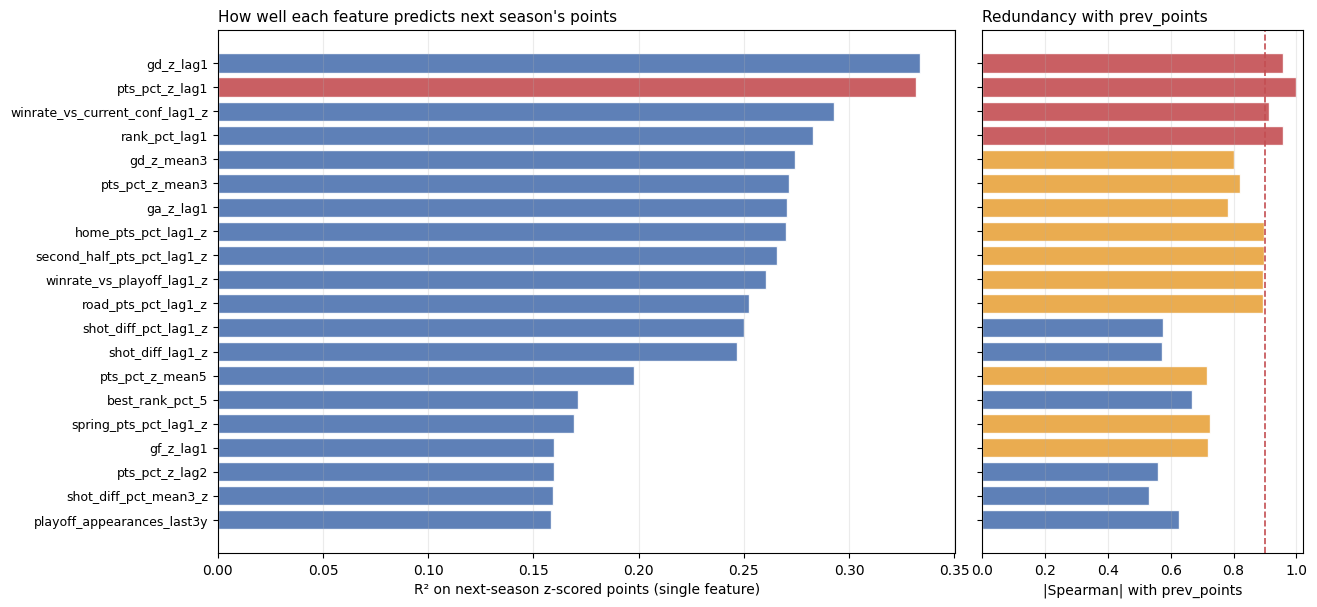

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_all_features = [c for cols in _all_groups.values() for c in cols]
_truth = _df[["year", "tmID", "target"]].drop_duplicates(["year", "tmID"])
_eval_years = [y for y in range(1995, 2010) if y in _df["year"].values]


def _single_r2(feat):
    p = ru.walk_forward(_dev, _make_model, [feat], _eval_years)
    m = p.merge(_truth, on=["year", "tmID"], how="left")
    ss_res = ((m["score"] - m["target"]) ** 2).sum()
    ss_tot = ((m["target"] - m["target"].mean()) ** 2).sum()
    return 1 - ss_res / ss_tot


_r2 = pd.Series({f: _single_r2(f) for f in _all_features}).sort_values(ascending=False)
_top = _r2.head(20)

_sub = _df[_df["n_hist"] >= 1]
_corr_with_prev = (
    _sub[_top.index]
    .apply(lambda c: c.corr(_sub["pts_pct_z_lag1"], method="spearman"))
    .abs()
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6.8),
    sharey=True,
    gridspec_kw={"width_ratios": [2.3, 1.0], "wspace": 0.05},
)

ax = axes[0]
y_pos = np.arange(len(_top))
colors = ["#C44E52" if f == "pts_pct_z_lag1" else "#4C72B0" for f in _top.index]
ax.barh(y_pos, _top.values, color=colors, alpha=0.9, edgecolor="white")
ax.set_yticks(y_pos)
ax.set_yticklabels(_top.index, fontsize=9)
ax.set_xlabel("R² on next-season z-scored points (single feature)")
ax.set_title(
    "How well each feature predicts next season's points", loc="left", fontsize=11
)
ax.invert_yaxis()
ax.grid(alpha=0.25, axis="x")

ax = axes[1]
corr_vals = _corr_with_prev.values
bar_colors = [
    "#C44E52" if c > 0.9 else "#E8A33D" if c > 0.7 else "#4C72B0" for c in corr_vals
]
ax.barh(y_pos, corr_vals, color=bar_colors, alpha=0.9, edgecolor="white")
ax.set_xlim(0, 1.02)
ax.axvline(0.9, color="#C44E52", ls="--", lw=1.2)
ax.set_xlabel("|Spearman| with prev_points")
ax.set_title("Redundancy with prev_points", loc="left", fontsize=11)
ax.grid(alpha=0.25, axis="x")

plt.tight_layout()
plt.show()

```
Here we can see that the previous rank is among the best feature for the training set to predict the next season points. 
We also can see that a lot of the other features that are also good at predicting, are highly correlated with the previous rank feature.

Those feature all express does the team has performed well last season.

Let's confirm this by checking how better is the correlation, using first the prev_score_feature, and let's see by how much is this increased by each features
```

C:\Users\barcl\AppData\Local\Temp\ipykernel_23180\1159515615.py:126: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


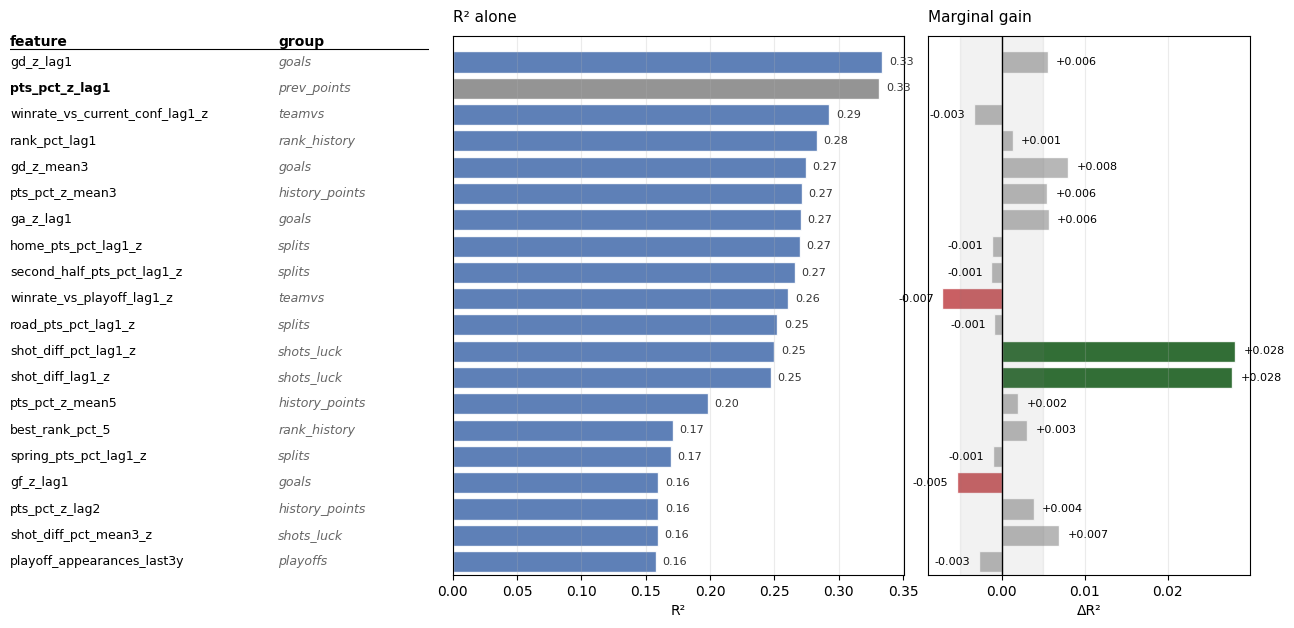

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_truth = _df[["year", "tmID", "target"]].drop_duplicates(["year", "tmID"])
_eval_years = [y for y in range(1995, 2010) if y in _df["year"].values]


def _r2_of(feats):
    p = ru.walk_forward(_dev, _make_model, feats, _eval_years)
    m = p.merge(_truth, on=["year", "tmID"], how="left")
    ss_res = ((m["score"] - m["target"]) ** 2).sum()
    ss_tot = ((m["target"] - m["target"].mean()) ** 2).sum()
    return 1 - ss_res / ss_tot


BASE = ["pts_pct_z_lag1"]
r2_base = _r2_of(BASE)

feat_to_group = {c: gname for gname, cols in _all_groups.items() for c in cols}

rows = []
for f, gname in feat_to_group.items():
    r2_alone = _r2_of([f])
    delta = 0.0 if f == "pts_pct_z_lag1" else _r2_of(BASE + [f]) - r2_base
    rows.append({"feature": f, "group": gname, "r2_alone": r2_alone, "delta_r2": delta})

feat_df = pd.DataFrame(rows)
top = feat_df.sort_values("r2_alone", ascending=False).head(20).reset_index(drop=True)


def _color(delta):
    if delta > 0.020:
        return "#1B5E20"
    if delta < -0.005:
        return "#C44E52"
    return "#B0B0B0"


fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 7),
    gridspec_kw={"width_ratios": [1.3, 1.4, 1.0], "wspace": 0.06},
)

y_pos = np.arange(len(top))
ylim = (len(top) - 0.5, -1.0)

ax = axes[0]
ax.set_xlim(0, 1)
ax.set_ylim(*ylim)
ax.axis("off")

ax.text(0.00, -0.75, "feature", fontsize=10, fontweight="bold", ha="left", va="center")
ax.text(0.64, -0.75, "group", fontsize=10, fontweight="bold", ha="left", va="center")
ax.plot([0, 1], [-0.5, -0.5], color="black", lw=0.8)

for i, r in top.iterrows():
    weight = "bold" if r["feature"] == "pts_pct_z_lag1" else "normal"
    ax.text(
        0.00, i, r["feature"], fontsize=9, ha="left", va="center", fontweight=weight
    )
    ax.text(
        0.64,
        i,
        r["group"],
        fontsize=9,
        ha="left",
        va="center",
        style="italic",
        color="#666",
    )

ax = axes[1]
ax.set_ylim(*ylim)
ax.set_yticks([])
ax.barh(
    y_pos,
    top["r2_alone"],
    color=["#888888" if f == "pts_pct_z_lag1" else "#4C72B0" for f in top["feature"]],
    alpha=0.9,
    edgecolor="white",
)
ax.set_title("R² alone", fontsize=11, loc="left", pad=10)
ax.set_xlabel("R²", fontsize=10)
ax.grid(alpha=0.25, axis="x")
for i, r in top.iterrows():
    ax.text(
        r["r2_alone"] + 0.005,
        i,
        f"{r['r2_alone']:.2f}",
        va="center",
        fontsize=8,
        color="#333",
    )

ax = axes[2]
ax.set_ylim(*ylim)
ax.set_yticks([])
ax.barh(
    y_pos,
    top["delta_r2"],
    color=[_color(v) for v in top["delta_r2"]],
    alpha=0.9,
    edgecolor="white",
)
ax.axvline(0, color="black", lw=1)
ax.axvspan(-0.005, 0.005, color="gray", alpha=0.10)
ax.set_title("Marginal gain", fontsize=11, loc="left", pad=10)
ax.set_xlabel("ΔR²", fontsize=10)
ax.grid(alpha=0.25, axis="x")
for i, r in top.iterrows():
    if r["feature"] == "pts_pct_z_lag1":
        continue
    v = r["delta_r2"]
    ax.text(
        v + 0.001 if v >= 0 else v - 0.001,
        i,
        f"{v:+.3f}",
        va="center",
        ha="left" if v >= 0 else "right",
        fontsize=8,
    )

plt.tight_layout()
plt.show()

```
This chart confirm that, a lot of features are expressing the same information, as the marginal gain is low.
Only exception is the shots_luck group, which shows an existing marginal gain on the prediction.
```

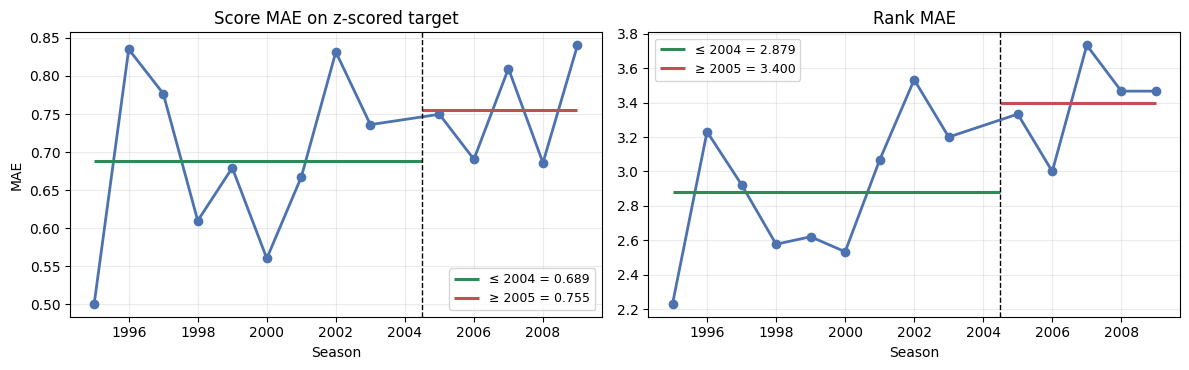

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_years = [y for y in range(1995, 2010) if y in _df["year"].values]
_p = pd.concat(
    [
        (
            _df.loc[_df["year"] == y, ["year", "tmID", "pts_pct_z_lag1"]]
            .rename(columns={"pts_pct_z_lag1": "score"})
            .dropna()
        )
        for y in _years
    ]
)
_truth = _df[["year", "tmID", "target"]].drop_duplicates(["year", "tmID"])
_m = _p.merge(_truth, on=["year", "tmID"], how="left")
_m["abs_err"] = (_m["score"] - _m["target"]).abs()
score_mae = _m.groupby("year")["abs_err"].mean()

persistence_all = ru.baseline_scores(_df, "pts_pct_z_lag1", _years)
rank_mae = (
    ru.season_metrics(ru.rank_predictions(persistence_all, _df))
    .groupby("year")["mae"].mean()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, s, title in zip(
    axes, [score_mae, rank_mae], ["Score MAE on z-scored target", "Rank MAE"]
):
    ax.plot(s.index, s.values, "o-", color="#4C72B0", lw=2)
    pre = s.loc[s.index <= 2004].mean()
    post = s.loc[s.index >= 2005].mean()
    ax.hlines(pre, 1995, 2004.5, color="#2E8B57", lw=2.2, label=f"≤ 2004 = {pre:.3f}")
    ax.hlines(post, 2004.5, 2009, color="#C44E52", lw=2.2, label=f"≥ 2005 = {post:.3f}")
    ax.axvline(2004.5, color="k", ls="--", lw=1)
    ax.set_xlabel("Season")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)
axes[0].set_ylabel("MAE")

plt.tight_layout()
plt.show()

```
This are the prediction of the naive model on the test (1980-2004) and train intervals (2004-2009)

We can see that the two interval are not as easily predicted by this model based only on the previous rank. The difficulty of the task is not the same. This is important because it implies that the train score will be a lot better than the test ones if we keep this separation.
```

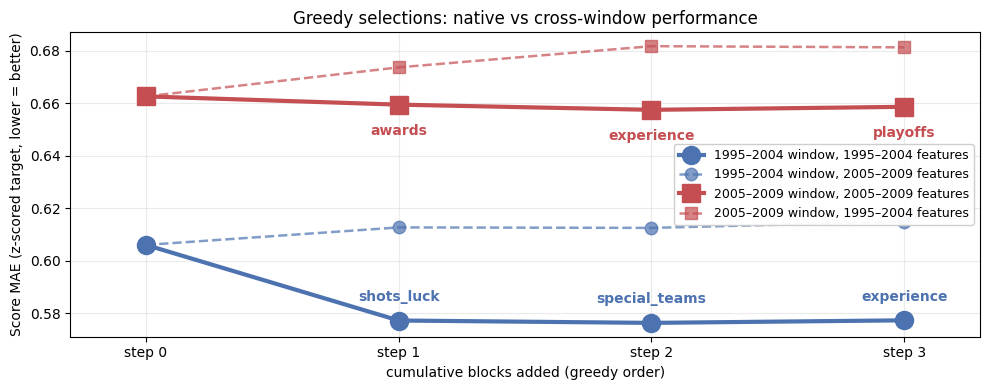

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_all_groups = {**ru.feature_groups(_df), **_ext_groups}
_pre_years = [y for y in range(1995, 2005) if y in _df["year"].values]
_post_years = [y for y in range(2005, 2010) if y in _df["year"].values]
_truth = _df[["year", "tmID", "target"]].drop_duplicates(["year", "tmID"])


def _score_mae(feats, years):
    p = ru.walk_forward(_df[_df["n_hist"] >= 1], _make_model, feats, years)
    m = p.merge(_truth, on=["year", "tmID"], how="left")
    return (m["score"] - m["target"]).abs().mean()


_blocks = [
    "shots_luck",
    "special_teams",
    "goalie",
    "roster",
    "experience",
    "playoffs",
    "awards",
    "teamvs",
]


def _greedy_tracked(select_years, other_years, max_blocks=3):
    current = ["pts_pct_z_lag1"]
    remaining = list(_blocks)
    hist = [
        {
            "step": 0,
            "block": "prev only",
            "mae_sel": _score_mae(current, select_years),
            "mae_oth": _score_mae(current, other_years),
        }
    ]
    n_blocks_added = 0
    while remaining and n_blocks_added < max_blocks:
        trials = {
            b: _score_mae(current + _all_groups[b], select_years) for b in remaining
        }
        best = min(trials, key=trials.get)
        current += _all_groups[best]
        n_blocks_added += 1
        hist.append(
            {
                "step": n_blocks_added,
                "block": best,
                "mae_sel": trials[best],
                "mae_oth": _score_mae(current, other_years),
            }
        )
        remaining.remove(best)
    return hist


hist_pre = _greedy_tracked(_pre_years, _post_years)
hist_post = _greedy_tracked(_post_years, _pre_years)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    [h["step"] for h in hist_pre],
    [h["mae_sel"] for h in hist_pre],
    "o-",
    color="#4C72B0",
    lw=3,
    ms=13,
    zorder=4,
    label="1995–2004 window, 1995–2004 features",
)

ax.plot(
    [h["step"] for h in hist_post],
    [h["mae_oth"] for h in hist_post],
    "o--",
    color="#4C72B0",
    lw=1.8,
    ms=9,
    alpha=0.7,
    zorder=3,
    label="1995–2004 window, 2005–2009 features",
)

ax.plot(
    [h["step"] for h in hist_post],
    [h["mae_sel"] for h in hist_post],
    "s-",
    color="#C44E52",
    lw=3,
    ms=13,
    zorder=4,
    label="2005–2009 window, 2005–2009 features",
)

ax.plot(
    [h["step"] for h in hist_pre],
    [h["mae_oth"] for h in hist_pre],
    "s--",
    color="#C44E52",
    lw=1.8,
    ms=9,
    alpha=0.7,
    zorder=3,
    label="2005–2009 window, 1995–2004 features",
)

for h in hist_pre:
    if h["step"] == 0:
        continue
    ax.annotate(
        h["block"],
        (h["step"], h["mae_sel"]),
        xytext=(0, 14),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        color="#4C72B0",
        fontweight="bold",
    )

for h in hist_post:
    if h["step"] == 0:
        continue
    ax.annotate(
        h["block"],
        (h["step"], h["mae_sel"]),
        xytext=(0, -22),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        color="#C44E52",
        fontweight="bold",
    )

n_steps = max(len(hist_pre), len(hist_post))
ax.set_xticks(range(n_steps))
ax.set_xticklabels([f"step {i}" for i in range(n_steps)], fontsize=10)
ax.set_xlim(-0.3, n_steps - 0.7)
ax.set_xlabel("cumulative blocks added (greedy order)")
ax.set_ylabel("Score MAE (z-scored target, lower = better)")
ax.grid(alpha=0.25)
ax.legend(fontsize=9, loc="center right", framealpha=0.95)
ax.set_title("Greedy selections: native vs cross-window performance")
plt.tight_layout()
plt.show()

```
This plots also reaveal another big issue. The features that helps to upgrade the prediction for the test and train interval, are not the same. The features that helps in one create noise in the other.

We can note that the higher complexity of the test interval appears here. We can clearly see that the MAE is higher for the test window (red).
```

# Case of changing context
---
```
As we saw the context is changing too much for us to be able to find stable features that works in the test interval and the training one. 

To pass this issue, we will try a method to find good features given the features that worked well in the previous seasons. The features will be adaptative given the past seasons.

We will then use LinearRegression to test this idea
```

=== Score MAE per test year ===


,persistence,ols_prev,k=2,k=3,k=5,k=7,k=9
year,,,,,,,
1995,0.501,0.509,0.581,0.581,0.527,0.581,0.581
1996,0.835,0.723,0.722,0.722,0.722,0.722,0.722
1997,0.777,0.692,0.692,0.709,0.709,0.709,0.671
1998,0.610,0.566,0.611,0.566,0.585,0.585,0.585
1999,0.679,0.483,0.483,0.483,0.406,0.406,0.406
2000,0.560,0.515,0.458,0.458,0.458,0.458,0.458
2001,0.667,0.618,0.551,0.551,0.529,0.529,0.551
2002,0.832,0.727,0.702,0.702,0.702,0.702,0.702
2003,0.736,0.611,0.584,0.604,0.604,0.604,0.604



=== Rank MAE per test year ===


,persistence,ols_prev,k=2,k=3,k=5,k=7,k=9
year,,,,,,,
1995,2.231,2.231,2.692,2.692,2.077,2.692,2.692
1996,3.231,3.231,3.077,3.077,3.077,3.077,3.077
1997,2.923,2.923,2.923,3.154,3.154,3.154,2.923
1998,2.577,2.458,2.946,2.458,2.530,2.530,2.530
1999,2.621,2.368,2.286,2.286,1.918,1.918,1.918
2000,2.533,2.277,1.754,1.754,1.754,1.754,1.754
2001,3.067,3.067,2.733,2.733,2.600,2.600,2.733
2002,3.533,3.533,2.867,2.867,2.867,2.867,2.867
2003,3.200,3.200,3.000,3.067,3.067,3.067,3.067



=== Summary (Δ vs ols_prev = the value of feature selection) ===


,score_MAE,rank_MAE,Δscore_vs_ols_prev,Δrank_vs_ols_prev
persistence,0.712,3.065,-0.087,-0.045
ols_prev,0.626,3.021,0.000,0.000
k=2,0.620,2.929,0.005,0.092
k=3,0.625,2.954,0.001,0.067
k=5,0.614,2.855,0.012,0.165
k=7,0.621,2.933,0.005,0.088
k=9,0.619,2.902,0.007,0.119



=== Selected blocks per year ===


window,k=2,k=3,k=5,k=7,k=9
year,,,,,
1995,shots_luck+goalie,shots_luck+goalie,shots_luck,shots_luck+goalie,shots_luck+goalie
1996,shots_luck,shots_luck,shots_luck,shots_luck,shots_luck
1997,prev only,shots_luck+playoffs+experience,shots_luck+playoffs+experience,shots_luck+playoffs+experience,shots_luck
1998,teamvs+goalie,prev only,shots_luck,shots_luck,shots_luck
1999,teamvs,teamvs,shots_luck,shots_luck,shots_luck
2000,shots_luck,shots_luck,shots_luck,shots_luck,shots_luck
2001,shots_luck,shots_luck,shots_luck+special_teams,shots_luck+special_teams,shots_luck
2002,shots_luck+special_teams,shots_luck+special_teams,shots_luck+special_teams,shots_luck+special_teams,shots_luck+special_teams
2003,shots_luck,shots_luck+special_teams,shots_luck+special_teams,shots_luck+special_teams,shots_luck+special_teams



=== Paired bootstrap on RANK MAE vs ols_prev ===


,strategy,rank_gain,ci_low,ci_high,signif
0,persistence,-0.020,-0.051,0.000,
1,k=2,0.083,-0.106,0.279,
2,k=3,0.075,-0.075,0.231,
3,k=5,0.170,0.035,0.327,*
4,k=7,0.095,-0.107,0.278,
5,k=9,0.125,-0.071,0.303,


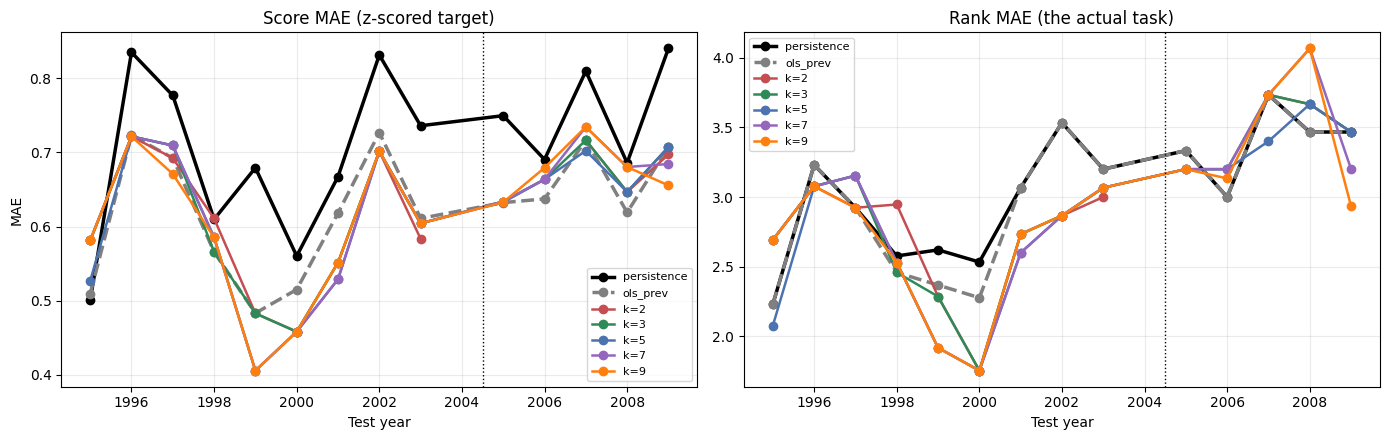

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from functools import lru_cache
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer


def _make_model():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LinearRegression(),
    )


_all_groups = {**ru.feature_groups(_df), **_ext_groups}
_truth = _df[["year", "tmID", "target"]].drop_duplicates(["year", "tmID"])
_dev = _df[_df["n_hist"] >= 1]
_blocks = ["shots_luck", "special_teams", "goalie", "roster",
           "experience", "playoffs", "awards", "teamvs"]


@lru_cache(maxsize=None)
def _mae_cached(feats_tuple, years_tuple):
    feats, years = list(feats_tuple), list(years_tuple)
    p = ru.walk_forward(_dev, _make_model, feats, years)
    m = p.merge(_truth, on=["year", "tmID"], how="left")
    return (m["score"] - m["target"]).abs().mean()


def _mae(feats, years):
    return _mae_cached(tuple(sorted(feats)), tuple(sorted(years)))


def _greedy(hist_years, min_gain, max_blocks):
    hist_years = sorted([y for y in hist_years if y in _df["year"].values])
    if len(hist_years) < 2:
        return ["pts_pct_z_lag1"], []
    current = ["pts_pct_z_lag1"]
    added = []
    remaining = list(_blocks)
    best = _mae(current, hist_years)
    while remaining and len(added) < max_blocks:
        trials = {b: _mae(current + _all_groups[b], hist_years) for b in remaining}
        cand = min(trials, key=trials.get)
        if best - trials[cand] < min_gain:
            break
        current += _all_groups[cand]
        best = trials[cand]
        added.append(cand)
        remaining.remove(cand)
    return current, added


WINDOWS = {
    "k=2": (2, 0.010, 2),
    "k=3": (3, 0.005, 3),
    "k=5": (5, 0.003, 3),
    "k=7": (7, 0.002, 3),
    "k=9": (9, 0.001, 3),
}
EVAL_YEARS = [y for y in range(1995, 2010) if y in _df["year"].values]
MIN_HISTORY_YEARS = 2


def _score_preds(feats, Y):
    p = ru.walk_forward(_dev, _make_model, feats, [Y])
    if "confID" not in p.columns:
        p = p.merge(_df[["year", "tmID", "confID"]].drop_duplicates(),
                    on=["year", "tmID"], how="left")
    truth = _df.loc[_df["year"] == Y, ["tmID", "target"]]
    p = p.merge(truth, on="tmID", how="left")
    p["abs_err"] = (p["score"] - p["target"]).abs()
    return p[["year", "tmID", "confID", "score", "abs_err"]]


def _persistence_preds(Y):
    p = (_df.loc[_df["year"] == Y, ["year", "tmID", "confID",
                                     "pts_pct_z_lag1", "target"]]
         .dropna(subset=["pts_pct_z_lag1"])
         .rename(columns={"pts_pct_z_lag1": "score"}))
    p["abs_err"] = (p["score"] - p["target"]).abs()
    return p[["year", "tmID", "confID", "score", "abs_err"]]


score_rows, sel_log = [], []
preds = {"persistence": [], "ols_prev": [], **{k: [] for k in WINDOWS}}

for Y in EVAL_YEARS:
    p_persist = _persistence_preds(Y)
    preds["persistence"].append(p_persist)

    p_ols_prev = _score_preds(["pts_pct_z_lag1"], Y)
    preds["ols_prev"].append(p_ols_prev)

    srow = {
        "year": Y,
        "persistence": p_persist["abs_err"].mean(),
        "ols_prev":    p_ols_prev["abs_err"].mean(),
    }
    for name, (k, min_gain, max_blocks) in WINDOWS.items():
        hist = sorted([y for y in _df["year"].unique() if Y - k <= y < Y])
        if len(hist) < MIN_HISTORY_YEARS:
            srow[name] = np.nan
            continue
        feats, added = _greedy(hist, min_gain, max_blocks)
        p = _score_preds(feats, Y)
        preds[name].append(p)
        srow[name] = p["abs_err"].mean()
        sel_log.append({"year": Y, "window": name,
                        "blocks": "+".join(added) if added else "prev only"})
    score_rows.append(srow)


def _rank_by_year(plist):
    pred = pd.concat(plist, ignore_index=True)
    ranked = ru.rank_predictions(pred[["year", "tmID", "confID", "score"]], _df)
    m = ru.season_metrics(ranked)
    return m.groupby("year")["mae"].mean()


score_res = pd.DataFrame(score_rows).set_index("year")
rank_res  = pd.DataFrame({name: _rank_by_year(plist) for name, plist in preds.items()})

print("=== Score MAE per test year ===")
display(score_res.round(3))
print("\n=== Rank MAE per test year ===")
display(rank_res.round(3))

summary = pd.DataFrame({
    "score_MAE": score_res.mean(),
    "rank_MAE":  rank_res.mean(),
})
summary["Δscore_vs_ols_prev"] = score_res["ols_prev"].mean() - summary["score_MAE"]
summary["Δrank_vs_ols_prev"]  = rank_res["ols_prev"].mean()  - summary["rank_MAE"]
print("\n=== Summary (Δ vs ols_prev = the value of feature selection) ===")
display(summary.round(3))

print("\n=== Selected blocks per year ===")
display(pd.DataFrame(sel_log).pivot(index="year", columns="window", values="blocks"))


def _stack_rank(plist):
    pred = pd.concat(plist, ignore_index=True)
    ranked = ru.rank_predictions(pred[["year", "tmID", "confID", "score"]], _df)
    return (ranked[["year", "tmID", "confID", "abs_err"]]
            .set_index(["year", "tmID"]).sort_index())


base_r = _stack_rank(preds["ols_prev"])
gid_r = (base_r["confID"] + "-" +
         base_r.index.get_level_values("year").astype(str)).to_numpy()

print("\n=== Paired bootstrap on RANK MAE vs ols_prev ===")
rank_boot = []
for name in ["persistence", "k=2", "k=3", "k=5", "k=7", "k=9"]:
    tgt = _stack_rank(preds[name]).reindex(base_r.index)
    b = base_r["abs_err"].to_numpy()
    r = tgt["abs_err"].to_numpy()
    mask = ~(np.isnan(b) | np.isnan(r))
    gain, (lo, hi) = ru.paired_bootstrap(b[mask], r[mask], gid_r[mask])
    rank_boot.append({
        "strategy": name,
        "rank_gain": round(gain, 3),
        "ci_low":  round(lo, 3),
        "ci_high": round(hi, 3),
        "signif":  "*" if lo > 0 else "",
    })
display(pd.DataFrame(rank_boot))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
colors = {
    "persistence": "black",
    "ols_prev":    "gray",
    "k=2": "#C44E52",
    "k=3": "#2E8B57",
    "k=5": "#4C72B0",
    "k=7": "#9467BD",
    "k=9": "#FF7F0E",
}

for ax, res, title in zip(
    axes,
    [score_res, rank_res],
    ["Score MAE (z-scored target)", "Rank MAE (the actual task)"],
):
    for name in ["persistence", "ols_prev", "k=2", "k=3", "k=5", "k=7", "k=9"]:
        style = "o--" if name == "ols_prev" else "o-"
        lw = 2.5 if name in ["persistence", "ols_prev"] else 1.8
        ax.plot(res.index, res[name], style, color=colors[name], lw=lw, label=name)
    ax.axvline(2004.5, color="k", ls=":", lw=1)
    ax.set_xlabel("Test year")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

axes[0].set_ylabel("MAE")
plt.tight_layout()
plt.show()

```
We can see here, that selecting features using the last 5 years is significatively better than just predicting with the prev_rank score
This confirm this is the method we will use for testing different models.
```